# Task 2: three frozen pretrained models + linear probes + ensemble

**Idea.** Large vision models trained on hundreds of millions of images already describe an image with numbers ("features") that separate our 10 classes almost perfectly. So we:
1. Take three pretrained models ("backbones"), trained in three very different ways, and **freeze** them: we never change their weights, we only use them to turn every image into one vector of numbers:
   - **DINOv2-L with registers** (`facebook/dinov2-with-registers-large`, 304M params, Apache-2.0). Self-supervised: learns by matching views of the same image, no labels.
   - **SigLIP2 So400m** (`google/siglip2-so400m-patch14-224`, Apache-2.0). Trained to match images with their captions, so its features encode semantic concepts.
   - **ConvNeXt-L** (`facebook/convnext-large-224-22k-1k`, 198M params, Apache-2.0). A CNN trained with labels on ImageNet-22k, then ImageNet-1k. Convolutions instead of attention, so it makes different mistakes.

   Each image goes in twice (as it is and mirrored) and we average the two vectors.
2. On top of each backbone, train a **logistic regression**: a simple classifier that gives each class a score (a weighted sum of the numbers) and turns the scores into probabilities. Its setting `C` is chosen on the validation split.
3. **Ensemble:** average the probabilities of several of these classifiers. We try every combination (each model alone, every pair, all three) on the validation split and keep the best for Kaggle. The test split is only reported, never used to choose.

Same split as Task 1 (`data/split.csv`). For the Kaggle file the probes are refit on all labelled images, and their weights are saved to `outputs/weights/task2.pth`.

*Caveat for the report:* RIVAL10 is built from ImageNet images. The backbones' pretraining data likely overlaps with ImageNet-like images, so accuracy may overstate generalization to truly new images. This is strongest for ConvNeXt, which was trained with ImageNet labels.

## 0. Colab setup (skipped automatically on a local machine)

Put two files in Google Drive under `MyDrive/ecse551/`: the Kaggle zip `fall-2026-ecse-551-task-1.zip` and `split.csv` (from `data/` in the repo). This cell mounts Drive, unzips the data to the fast local disk, and saves everything in `outputs/` to `MyDrive/ecse551/outputs` so results survive the end of the session.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE, ROOT = "/content/drive/MyDrive/ecse551", "/content/ecse551"
    if not os.path.exists(f"{ROOT}/data/fall-2026-ecse-551-task-1"):
        os.makedirs(f"{ROOT}/data", exist_ok=True)
        os.system(f"unzip -q '{DRIVE}/fall-2026-ecse-551-task-1.zip' -d {ROOT}/data/fall-2026-ecse-551-task-1")
    if os.path.exists(f"{DRIVE}/split.csv"): os.system(f"cp '{DRIVE}/split.csv' {ROOT}/data/")
    os.makedirs(f"{DRIVE}/outputs", exist_ok=True); os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
    if not os.path.exists(f"{ROOT}/outputs"): os.symlink(f"{DRIVE}/outputs", f"{ROOT}/outputs")
    os.chdir(f"{ROOT}/notebooks")
    print("Colab ready:", os.listdir(f"{ROOT}/data"))

Mounted at /content/drive
Colab ready: ['split.csv', 'fall-2026-ecse-551-task-1']


In [2]:
import os, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from itertools import combinations                            # to list every subset of models
from PIL import Image                                         # to open image files
from transformers import AutoModel, AutoImageProcessor        # Hugging Face: download pretrained models
from sklearn.linear_model import LogisticRegression           # the linear classifier we train
from sklearn.metrics import ConfusionMatrixDisplay

PATH = "../data/fall-2026-ecse-551-task-1"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # GPU if available
encodings = {"truck": 0, "frog": 1, "cat": 2, "plane": 3, "bird": 4, "car": 5, "equine": 6, "ship": 7, "deer": 8, "dog": 9}   # same as Task 1
classes = list(encodings)                                     # classes[3] == "plane": number -> name

# Full path of every image file
train = pd.read_csv(f"{PATH}/train.csv")                      # 21,098 labelled images
test = pd.read_csv(f"{PATH}/test.csv")                        # 5,286 Kaggle images, no labels
train["path"] = PATH + "/archive/RIVAL10_Kaggle" + train["image_path"].str[7:]   # drop the leading "RIVAL10"
test["path"] = PATH + "/archive/RIVAL10_Kaggle/test/test_images/" + test["id"]
y = train["label_name"].map(encodings).values                 # labels as numbers 0-9

# Same train / validation / test split as the CNN and the ViT (row i of split.csv = image i of train.csv)
split = pd.read_csv("../data/split.csv")
assert (split["image_path"] == train["image_path"]).all(), "split.csv rows must match train.csv"
split = split["split"]
tr, va, te = (np.where(split == s)[0] for s in ("train", "val", "test"))   # row numbers of each part

# The three pretrained models (names on huggingface.co)
BACKBONES = {"dinov2": "facebook/dinov2-with-registers-large",
             "siglip2": "google/siglip2-so400m-patch14-224",
             "convnext": "facebook/convnext-large-224-22k-1k"}

## 1. Feature extraction

Each backbone turns an image into one vector of numbers (a "feature vector"):
- **DINOv2** and **ConvNeXt**: the model's summary of the whole image (`pooler_output`).
- **SigLIP2**: its image vector (`get_image_features`), the one it learned to match with text descriptions of the image.

Each model comes with an "image processor" that resizes and normalizes the image the way the model expects. We use the image and its mirror image and average the two vectors. Then we scale every vector to length 1, so the numbers of the three models are on the same scale.

The models are **frozen**: we never change their weights, we only read their output. Features are saved in `outputs/features/` (Drive on Colab), so a rerun skips this step, which is the slow part (~5–10 min per model on a T4).

In [3]:
def embed(model, x):
    """Batch of images x -> one feature vector per image."""
    if hasattr(model, "get_image_features"):                   # SigLIP2 (image + text model): ask for the image part only
        out = model.get_image_features(pixel_values=x)
    else:                                                      # DINOv2 and ConvNeXt (image-only models)
        out = model(pixel_values=x).pooler_output
    out = getattr(out, "pooler_output", out)                   # some library versions wrap the vector in an object
    return out.flatten(1)                                      # shape (batch, feature size)

@torch.no_grad()                                               # no training here, so no gradients (faster, less memory)
def features(name, paths, tag, bs=64):
    """Feature vectors of all images in `paths` for backbone `name`. Saved to disk the first time."""
    file = f"../outputs/features/{name}_{tag}.pt"
    if os.path.exists(file):                                   # already computed in an earlier run
        return torch.load(file)
    proc = AutoImageProcessor.from_pretrained(BACKBONES[name])                           # resize/crop/normalize like in pretraining
    model = AutoModel.from_pretrained(BACKBONES[name]).to(device, torch.float16).eval()  # 16-bit numbers: about 2x faster
    out = []
    for i in range(0, len(paths), bs):                          # bs images at a time
        images = [Image.open(p).convert("RGB") for p in paths[i:i + bs]]
        x = proc(images=images, return_tensors="pt")["pixel_values"].to(device, torch.float16)
        v = (embed(model, x) + embed(model, x.flip(3))) / 2     # average of image and mirror image (flip the width axis)
        out.append(v.float().cpu())
    f = torch.cat(out)                                          # (number of images, feature size)
    f = f / f.norm(dim=1, keepdim=True)                         # every vector gets length 1
    os.makedirs("../outputs/features", exist_ok=True)
    torch.save(f, file)
    return f

In [4]:
# feats["dinov2"] = (features of the 21,098 labelled images, features of the 5,286 Kaggle images); same for the others
feats = {n: (features(n, train["path"].tolist(), "train"), features(n, test["path"].tolist(), "test")) for n in BACKBONES}
{n: tuple(f.shape) for n, (f, _) in feats.items()}             # (images, feature size) per backbone

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/440 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/440 [00:00<?, ?it/s]

... (14 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/342 [00:00<?, ?it/s]

[transformers] ConvNextModel LOAD REPORT from: facebook/convnext-large-224-22k-1k
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'dinov2': (21098, 1024), 'siglip2': (21098, 1152), 'convnext': (21098, 1536)}

## 2. One linear probe per backbone

A **logistic regression** learns one weight per feature and per class. The score of a class is the weighted sum of the features, and the 10 scores are turned into probabilities (softmax). It is trained on the training split only. `C` controls how simple the classifier must stay: small `C` = simpler, less risk of overfitting. We try `C` in {1, 3, 10, 30, 100} and keep the value with the best **validation** accuracy.

The table shows the validation accuracy for every (backbone, `C`) pair.

In [5]:
def acc(p, idx):
    """Accuracy of the probabilities p (one row per image) against the true labels of rows idx."""
    return (p.argmax(1) == y[idx]).mean()

probs = {}    # probs["dinov2"]["val"] = class probabilities for every validation image
best_C = {}   # best C per backbone
rows = []     # for the table
for n, (F, _) in feats.items():                                # F = features of the labelled images
    F = F.numpy()
    fits = {C: LogisticRegression(C=C, max_iter=3000).fit(F[tr], y[tr]) for C in (1, 3, 10, 30, 100)}   # train on the train split only
    val = {C: acc(m.predict_proba(F[va]), va) for C, m in fits.items()}                                  # score each on validation
    best_C[n] = max(val, key=val.get)                                                                   # keep the best C
    probs[n] = {s: fits[best_C[n]].predict_proba(F[idx]) for s, idx in (("val", va), ("test", te))}
    rows.append({"backbone": n, **{f"val C={C}": v for C, v in val.items()}})
pd.DataFrame(rows).round(4)

,backbone,val C=1,val C=3,val C=10,val C=30,val C=100
0,dinov2,0.9975,0.9978,0.9981,0.9978,0.9978
1,siglip2,0.9981,0.9975,0.9975,0.9981,0.9987
2,convnext,0.9984,0.9987,0.9984,0.9984,0.9987


## 3. Ensemble: every subset of the three probes

An ensemble averages the probabilities of its members. We try all 7 combinations (each model alone, the 3 pairs, all three) on the validation split and keep the best one; if two are equal we keep the bigger one. The test column is only reported, never used to choose.

In [6]:
def mix(c, s):
    """Ensemble of the models in c (e.g. ("dinov2", "convnext")): average of their probabilities on split s."""
    return np.mean([probs[n][s] for n in c], 0)

combos = [c for k in range(1, len(feats) + 1) for c in combinations(feats, k)]   # 3 singles + 3 pairs + 1 triple = 7
best = max(combos, key=lambda c: (acc(mix(c, "val"), va), len(c)))               # best validation accuracy; on a tie, more models
print("chosen:", " + ".join(best), "| C:", {n: best_C[n] for n in best})
pd.DataFrame([(" + ".join(c), acc(mix(c, "val"), va), acc(mix(c, "test"), te)) for c in combos],
             columns=["models", "val acc", "test acc"]).round(4)

chosen: dinov2 + convnext | C: {'dinov2': 10, 'convnext': 3}


,models,val acc,test acc
0,dinov2,0.9981,0.9968
1,siglip2,0.9987,0.9975
2,convnext,0.9987,0.9981
3,dinov2 + siglip2,0.9981,0.9975
4,dinov2 + convnext,0.9994,0.9978
5,siglip2 + convnext,0.9991,0.9981
6,dinov2 + siglip2 + convnext,0.9991,0.9981


## 4. Where does the chosen ensemble still fail? (our test split)

truck     0.993
frog      1.000
cat       1.000
plane     1.000
bird      1.000
car       0.991
equine    0.997
ship      1.000
deer      1.000
dog       0.997
Name: per-class test acc, dtype: float64


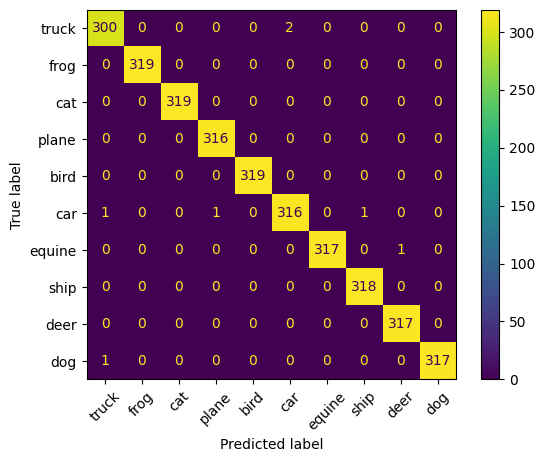

In [7]:
pred = mix(best, "test").argmax(1)                              # predicted class of each test-split image
print(pd.Series({c: (pred[y[te] == i] == i).mean() for c, i in encodings.items()}, name="per-class test acc").round(3))
# Rows = true class, columns = predicted class; everything off the diagonal is a mistake
ConfusionMatrixDisplay.from_predictions(y[te], pred, display_labels=classes, xticks_rotation=45, values_format="d"); plt.show()

## 5. Final model: refit on all labelled images and save its weights

The "Task 2 weights" we submit are the weights of the chosen logistic regressions. The backbones are public models that we never changed, so the file only stores their Hugging Face names. For this final version we train on all labelled images (train + val + test), with the `C` values chosen above.

In [8]:
# Same C as chosen above, but trained on all 21,098 labelled images (more data = slightly better model for Kaggle)
final = {n: LogisticRegression(C=best_C[n], max_iter=3000).fit(feats[n][0].numpy(), y) for n in best}

# A logistic regression is just a table of weights (10 classes x number of features) and one bias per class
os.makedirs("../outputs/weights", exist_ok=True)
torch.save({n: {"backbone": BACKBONES[n], "C": best_C[n], "coef": torch.tensor(m.coef_), "intercept": torch.tensor(m.intercept_)}
            for n, m in final.items()},
           "../outputs/weights/task2.pth")

Check: reload the saved weights and recompute the probabilities by hand (softmax of features · weights + bias). They must match the fitted models.

In [9]:
W = torch.load("../outputs/weights/task2.pth")
# For each model: scores = features x weights + bias, softmax turns them into probabilities; then average over the chosen models
P = np.mean([torch.softmax(feats[n][1].double() @ W[n]["coef"].double().T + W[n]["intercept"].double(), 1).numpy() for n in W], 0)
assert np.allclose(P, np.mean([final[n].predict_proba(feats[n][1].numpy()) for n in best], 0), atol=1e-6)
print("saved weights reproduce the predictions")

saved weights reproduce the predictions


## 6. Kaggle file (Task 2 competition, not submitted yet)

In [10]:
# Kaggle format: id = image number ("00042.png" -> 42), label_name = predicted class name
os.makedirs("../outputs/submissions", exist_ok=True)
pd.DataFrame({"id": test["id"].str[:5].astype(int), "label_name": [classes[i] for i in P.argmax(1)]}).to_csv("../outputs/submissions/task2.csv", index=False)
pd.read_csv("../outputs/submissions/task2.csv")["label_name"].value_counts()   # sanity check: about 530 per class

,count
label_name,
car,536
bird,533
cat,532
equine,532
ship,532
dog,531
deer,531
plane,530
frog,530
